# 🏪 SuperStore Sales - Exploratory Data Analysis

This notebook performs a comprehensive exploratory data analysis (EDA) on the SuperStore global sales dataset. We'll explore sales trends, product performance, geographic insights, customer segments, and more to uncover actionable business insights.

**Dataset:** SuperStore cleaned data (51,290 transactions from 2011–2014)  
**Goal:** Identify key drivers of sales and profit, and spot areas for improvement.

---

## Table of Contents
1. [Setup & Data Loading](#1.-Setup-&-Data-Loading)
2. [Overview KPIs](#2.-Overview-KPIs)
3. [Time Series Analysis](#3.-Time-Series-Analysis)
4. [Product Analysis](#4.-Product-Analysis)
5. [Geographic Analysis](#5.-Geographic-Analysis)
6. [Customer Analysis](#6.-Customer-Analysis)
7. [Discount Analysis](#7.-Discount-Analysis)
8. [Shipping Analysis](#8.-Shipping-Analysis)
9. [Key Findings & Conclusions](#9.-Key-Findings-&-Conclusions)

---
## 1. Setup & Data Loading

First, we import the libraries we need and load the cleaned dataset.

In [1]:
# --- Import Libraries ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

# Render plots inline in the notebook
%matplotlib inline

# --- Display Settings ---
# Format floats with commas and 2 decimal places for readability
pd.options.display.float_format = '{:,.2f}'.format
pd.set_option('display.max_columns', 30)

# Set a clean, professional chart style
sns.set_style("whitegrid")

# Define a consistent color palette used throughout the notebook
PALETTE = sns.color_palette("Set2", 10)
ACCENT = "#2196F3"   # Primary blue accent
COLORS = {
    'blue':   '#2196F3',
    'green':  '#4CAF50',
    'red':    '#F44336',
    'orange': '#FF9800',
    'purple': '#9C27B0',
    'teal':   '#009688',
    'grey':   '#607D8B'
}

# Suppress minor warnings to keep output clean
warnings.filterwarnings('ignore')

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


In [2]:
# --- Load the Cleaned Dataset ---
# The cleaned CSV is in the processed data folder, one level up from notebooks/
df = pd.read_csv('../data/processed/superstore_cleaned.csv')

# Convert date columns to datetime so we can do time-based analysis
df['order_date'] = pd.to_datetime(df['order_date'])
df['ship_date'] = pd.to_datetime(df['ship_date'])

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range: {df['order_date'].min().date()} to {df['order_date'].max().date()}")

Dataset loaded: 51,290 rows × 26 columns
Date range: 2011-01-01 to 2014-12-31


In [3]:
# --- Quick Overview ---
# Look at the first few rows to understand the structure
df.head()

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year,month,quarter,order_month,shipping_days,profit_margin
0,AG-2011-2040,2011-01-01,2011-01-06,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.00,106.14,35.46,Medium,2011,1,1,2011-01,5,0.26
1,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.10,36.04,9.72,Medium,2011,1,1,2011-01,7,0.30
2,HU-2011-1220,2011-01-01,2011-01-05,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.00,29.64,8.17,High,2011,1,1,2011-01,4,0.45
3,IT-2011-3647632,2011-01-01,2011-01-05,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.50,-26.05,4.82,High,2011,1,1,2011-01,4,-0.58
4,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.10,37.77,4.70,Medium,2011,1,1,2011-01,7,0.33


In [4]:
# Check data types and confirm there are no missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        51290 non-null  str           
 1   order_date      51290 non-null  datetime64[us]
 2   ship_date       51290 non-null  datetime64[us]
 3   ship_mode       51290 non-null  str           
 4   customer_name   51290 non-null  str           
 5   segment         51290 non-null  str           
 6   state           51290 non-null  str           
 7   country         51290 non-null  str           
 8   market          51290 non-null  str           
 9   region          51290 non-null  str           
 10  product_id      51290 non-null  str           
 11  category        51290 non-null  str           
 12  sub_category    51290 non-null  str           
 13  product_name    51290 non-null  str           
 14  sales           51290 non-null  int64         
 15  quantity     

In [5]:
# Summary statistics for the numeric columns
df.describe()

,order_date,ship_date,sales,quantity,discount,profit,shipping_cost,year,month,quarter,shipping_days,profit_margin
count,51290,51290,"51,290.00","51,290.00","51,290.00","51,290.00","51,290.00","51,290.00","51,290.00","51,290.00","51,290.00","51,290.00"
mean,2013-05-11 21:26:49.155780,2013-05-15 20:42:42.745174,246.50,3.48,0.14,28.64,26.38,"2,012.78",7.52,2.79,3.97,0.05
min,2011-01-01 00:00:00,2011-01-03 00:00:00,0.00,1.00,0.00,"-6,599.98",0.00,"2,011.00",1.00,1.00,0.00,-4.73
25%,2012-06-19 00:00:00,2012-06-23 00:00:00,31.00,2.00,0.00,0.00,2.61,"2,012.00",5.00,2.00,3.00,0.00
50%,2013-07-08 00:00:00,2013-07-12 00:00:00,85.00,3.00,0.00,9.24,7.79,"2,013.00",8.00,3.00,4.00,0.17
75%,2014-05-22 00:00:00,2014-05-26 00:00:00,251.00,5.00,0.20,36.81,24.45,"2,014.00",10.00,4.00,5.00,0.33
max,2014-12-31 00:00:00,2015-01-07 00:00:00,"22,638.00",14.00,0.85,"8,399.98",933.57,"2,014.00",12.00,4.00,7.00,0.58
std,NaN,NaN,487.57,2.28,0.21,174.42,57.30,1.10,3.30,1.07,1.73,0.47


---
## 2. Overview KPIs

Let's compute the headline metrics that summarize overall business performance.

In [6]:
# --- Calculate Key Performance Indicators ---

total_sales = df['sales'].sum()
total_profit = df['profit'].sum()
total_orders = df['order_id'].nunique()
avg_order_value = total_sales / total_orders
overall_profit_margin = (total_profit / total_sales) * 100
total_quantity = df['quantity'].sum()
total_customers = df['customer_name'].nunique()
loss_making_rows = (df['profit'] < 0).sum()
loss_making_pct = (loss_making_rows / len(df)) * 100

# Display the KPIs in a clean format
print("=" * 55)
print("       📊  SUPERSTORE — KEY PERFORMANCE INDICATORS")
print("=" * 55)
print(f"  💰  Total Sales:          ${total_sales:>14,.2f}")
print(f"  📈  Total Profit:         ${total_profit:>14,.2f}")
print(f"  📦  Total Orders:          {total_orders:>13,}")
print(f"  🛒  Avg Order Value:      ${avg_order_value:>14,.2f}")
print(f"  📊  Profit Margin:         {overall_profit_margin:>13.2f}%")
print(f"  👥  Unique Customers:      {total_customers:>13,}")
print(f"  📉  Loss-Making Rows:      {loss_making_rows:>13,} ({loss_making_pct:.1f}%)")
print("=" * 55)

       📊  SUPERSTORE — KEY PERFORMANCE INDICATORS
  💰  Total Sales:          $ 12,642,905.00
  📈  Total Profit:         $  1,469,034.82
  📦  Total Orders:                 25,035
  🛒  Avg Order Value:      $        505.01
  📊  Profit Margin:                 11.62%
  👥  Unique Customers:                795
  📉  Loss-Making Rows:             12,543 (24.5%)


**📌 Business Interpretation — KPIs:**

The KPIs above give us a top-level health check of the business. Pay attention to the profit margin — it tells us how efficiently the company converts revenue into profit. A significant share of individual line items are loss-making, which warrants investigation into discounting practices and product-level profitability.

---
## 3. Time Series Analysis

Understanding how sales and profit evolve over time helps identify growth trends and seasonal patterns.

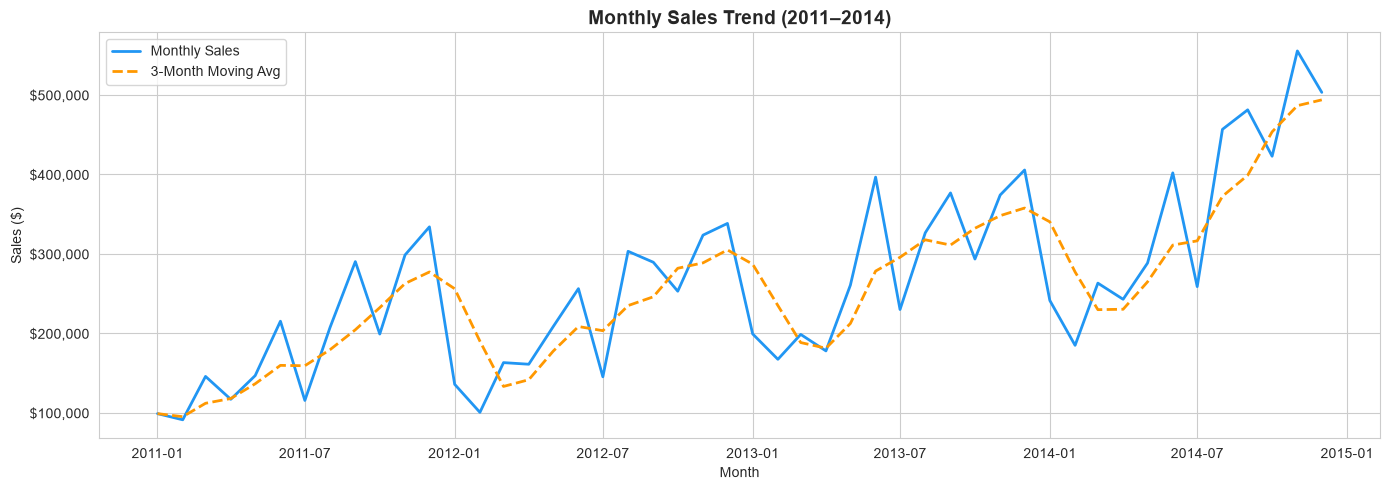

In [7]:
# --- 3.1  Monthly Sales Trend ---
# Group by the year-month of the order to see the monthly revenue trajectory
monthly_sales = df.groupby(df['order_date'].dt.to_period('M')).agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).reset_index()
monthly_sales['order_date'] = monthly_sales['order_date'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_sales['order_date'], monthly_sales['sales'],
        color=COLORS['blue'], linewidth=2, label='Monthly Sales')
# Add a 3-month rolling average to smooth out noise
ax.plot(monthly_sales['order_date'],
        monthly_sales['sales'].rolling(3, min_periods=1).mean(),
        color=COLORS['orange'], linewidth=2, linestyle='--', label='3-Month Moving Avg')
ax.set_title('Monthly Sales Trend (2011–2014)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Sales ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend()
plt.tight_layout()
plt.show()

**📌 Interpretation — Monthly Sales Trend:**

The monthly sales chart reveals an upward trajectory over the four-year period, indicating healthy top-line growth. Notice the recurring spikes — these typically correspond to end-of-year holiday seasons (November–December), pointing to strong seasonality in the business.

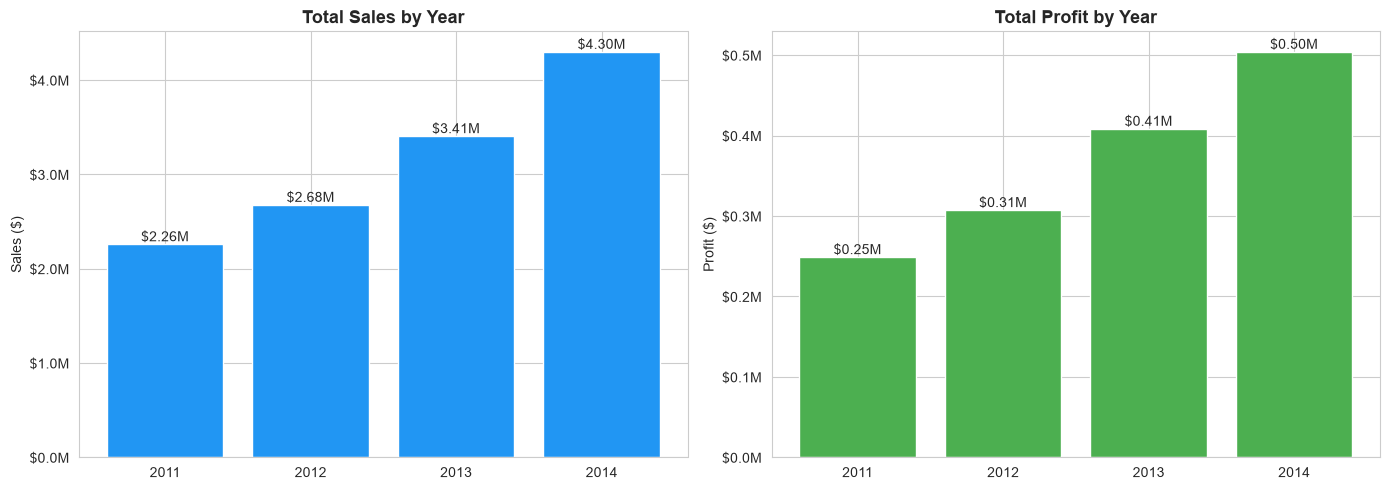

In [8]:
# --- 3.2  Yearly Sales & Profit ---
# Compare total sales and profit across each year
yearly = df.groupby('year').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Yearly Sales bar chart
bars1 = axes[0].bar(yearly['year'].astype(str), yearly['sales'], color=COLORS['blue'], edgecolor='white')
axes[0].set_title('Total Sales by Year', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
# Add value labels on top of each bar
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'${bar.get_height()/1e6:.2f}M', ha='center', va='bottom', fontsize=10)

# Yearly Profit bar chart
bars2 = axes[1].bar(yearly['year'].astype(str), yearly['profit'], color=COLORS['green'], edgecolor='white')
axes[1].set_title('Total Profit by Year', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Profit ($)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f'${bar.get_height()/1e6:.2f}M', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

**📌 Interpretation — Yearly Performance:**

Both sales and profit show consistent year-over-year growth. This suggests the SuperStore is successfully expanding its customer base and/or increasing order values. The profit growth rate relative to sales growth is worth monitoring — if profit grows slower than sales, margin pressure may be building.

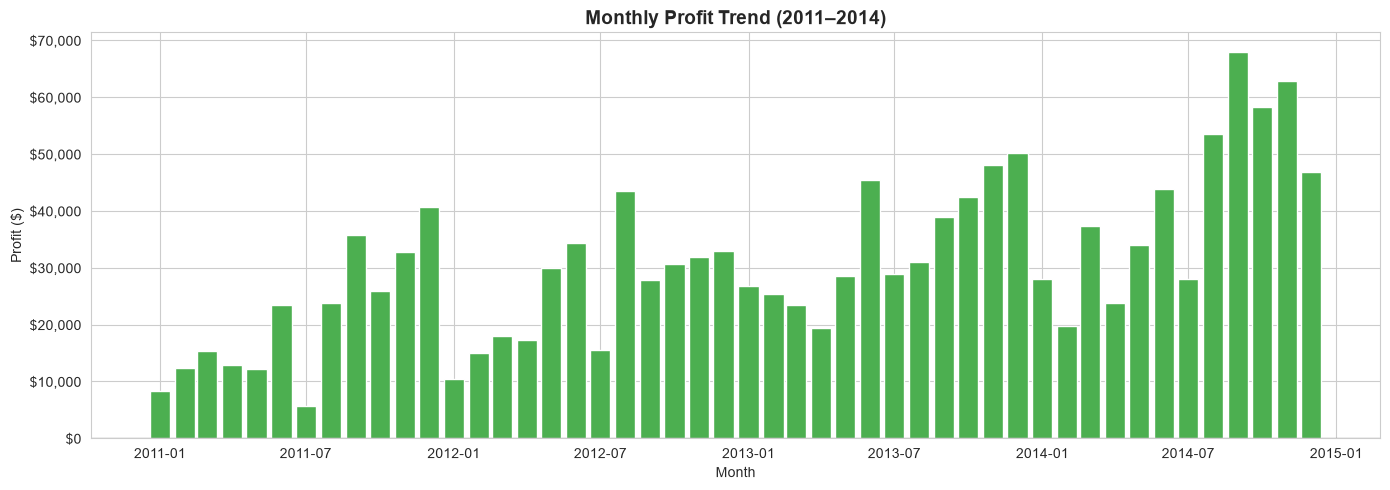

In [9]:
# --- 3.3  Monthly Profit Trend ---
fig, ax = plt.subplots(figsize=(14, 5))

# Color bars green for profit, red for loss months
colors = [COLORS['green'] if p >= 0 else COLORS['red'] for p in monthly_sales['profit']]
ax.bar(monthly_sales['order_date'], monthly_sales['profit'], color=colors, width=25)
ax.axhline(y=0, color='black', linewidth=0.8)  # zero line
ax.set_title('Monthly Profit Trend (2011–2014)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Profit ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Monthly Profit Trend:**

While most months are profitable, any red bars indicate months where cumulative discounts, shipping costs, or product mix caused net losses. These months deserve closer inspection to understand what went wrong.

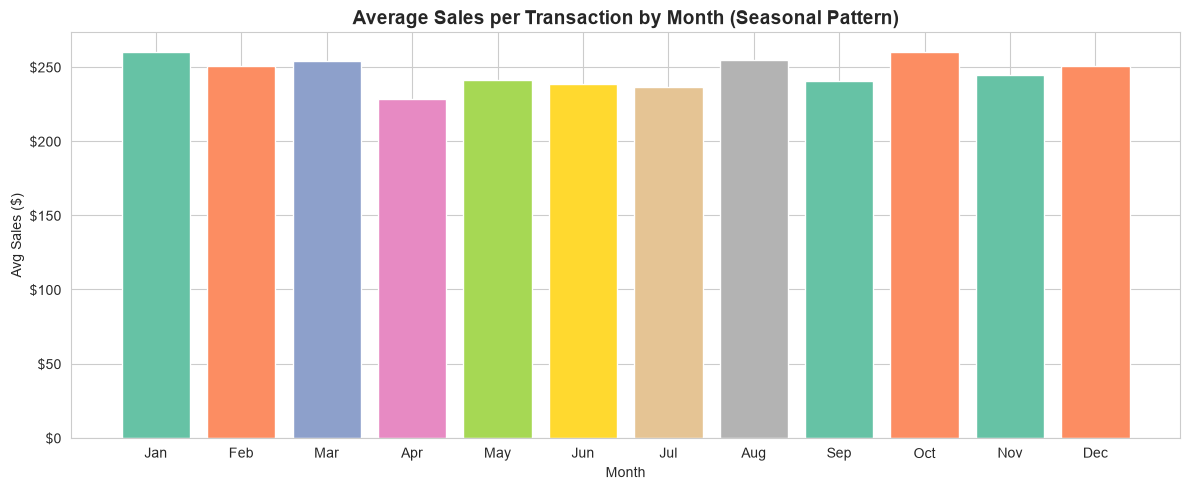

In [10]:
# --- 3.4  Seasonal Patterns (Average Sales by Month of Year) ---
# Average across all years to see the typical seasonal pattern
seasonal = df.groupby('month')['sales'].mean().reset_index()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(seasonal['month'], seasonal['sales'], color=PALETTE, edgecolor='white')
ax.set_title('Average Sales per Transaction by Month (Seasonal Pattern)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Avg Sales ($)')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Seasonality:**

The seasonal pattern helps the business plan inventory and marketing. If certain months consistently underperform, targeted promotions can help smooth revenue. Peak months should be staffed and stocked accordingly to maximize revenue capture.

---
## 4. Product Analysis

Understanding which products and categories drive revenue — and which destroy profit — is essential for strategic decisions.

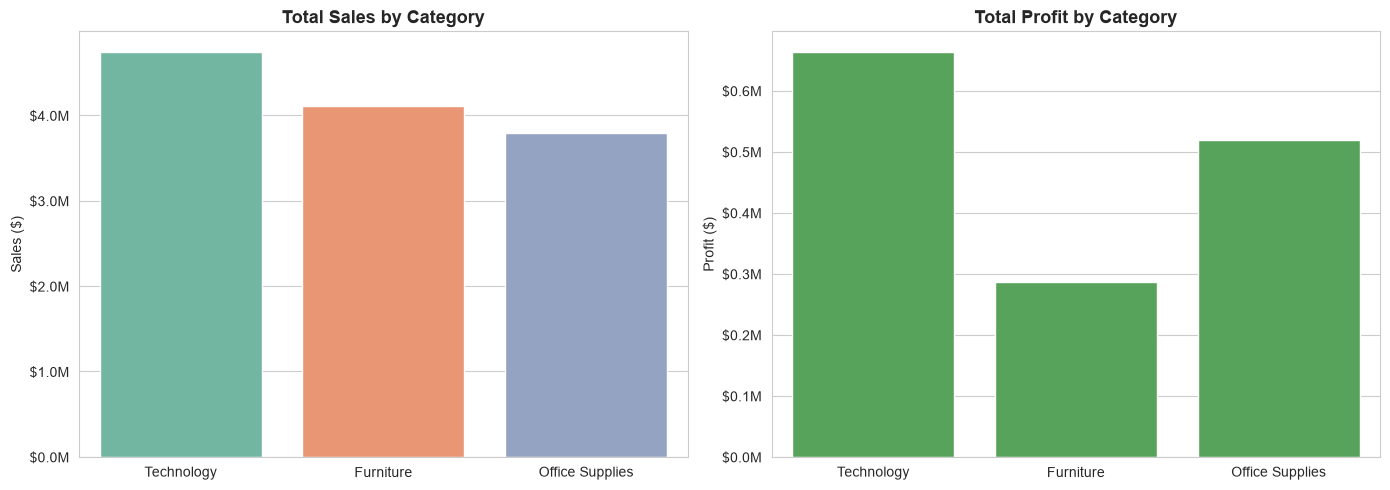

In [11]:
# --- 4.1  Sales & Profit by Category ---
cat_perf = df.groupby('category').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum'),
    quantity=('quantity', 'sum')
).sort_values('sales', ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales by Category
sns.barplot(data=cat_perf, x='category', y='sales', palette='Set2', ax=axes[0], edgecolor='white')
axes[0].set_title('Total Sales by Category', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].set_xlabel('')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

# Profit by Category
profit_colors = [COLORS['green'] if p >= 0 else COLORS['red'] for p in cat_perf['profit']]
sns.barplot(data=cat_perf, x='category', y='profit', palette=profit_colors, ax=axes[1], edgecolor='white')
axes[1].set_title('Total Profit by Category', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

**📌 Interpretation — Category Performance:**

This view highlights the revenue contribution and profitability of each product category. A category with high sales but low profit indicates margin issues — possibly driven by heavy discounting or high shipping costs. The most profitable category should be further invested in.

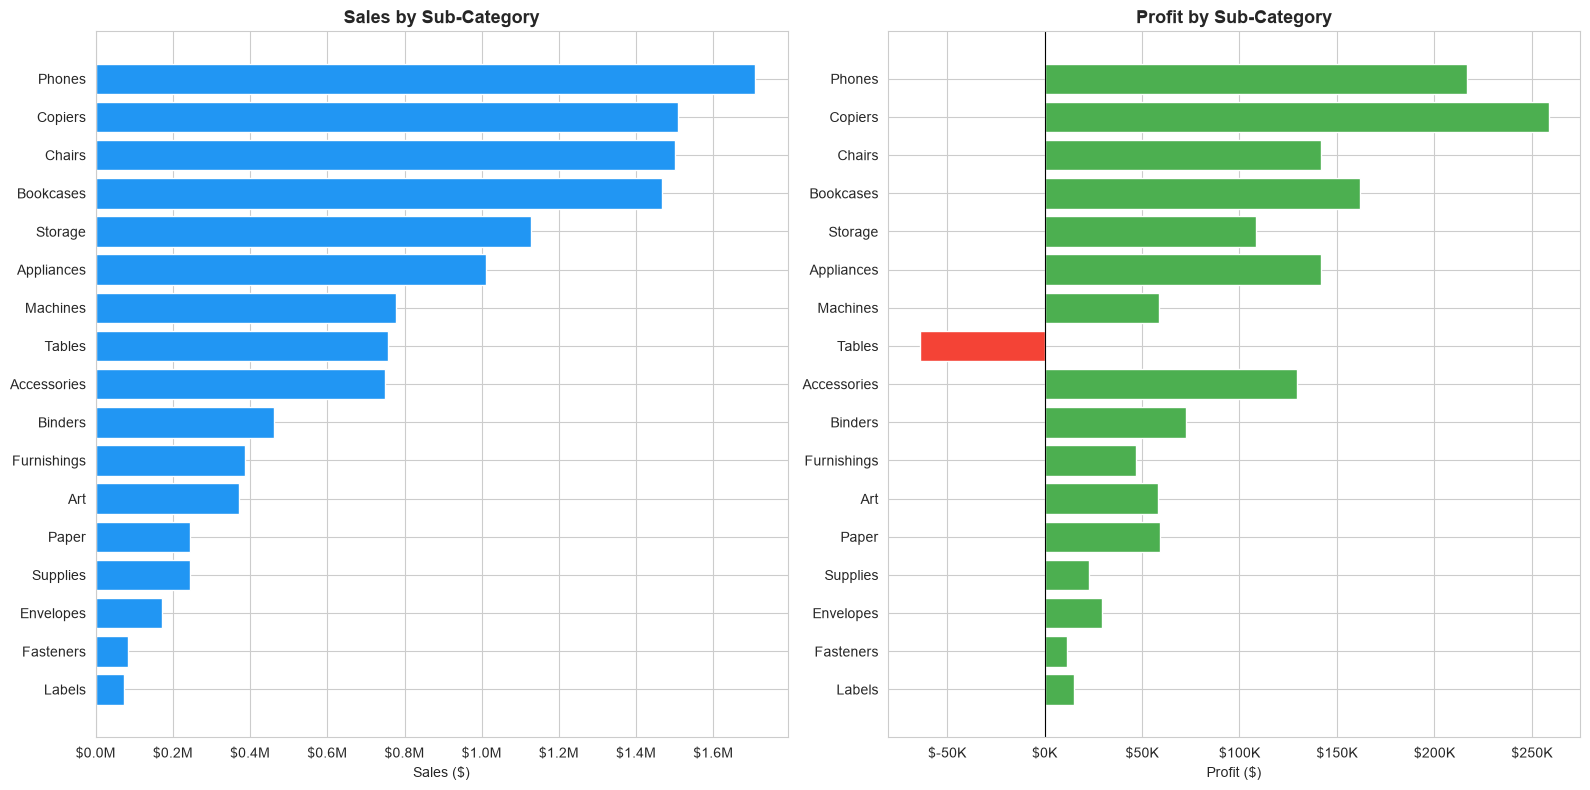

In [12]:
# --- 4.2  Sales & Profit by Sub-Category ---
subcat_perf = df.groupby('sub_category').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).sort_values('sales', ascending=True).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Sales by Sub-Category (horizontal bar for readability)
axes[0].barh(subcat_perf['sub_category'], subcat_perf['sales'], color=COLORS['blue'], edgecolor='white')
axes[0].set_title('Sales by Sub-Category', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sales ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

# Profit by Sub-Category — color red if negative
profit_colors_sub = [COLORS['green'] if p >= 0 else COLORS['red'] for p in subcat_perf['profit']]
axes[1].barh(subcat_perf['sub_category'], subcat_perf['profit'], color=profit_colors_sub, edgecolor='white')
axes[1].set_title('Profit by Sub-Category', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Profit ($)')
axes[1].axvline(x=0, color='black', linewidth=0.8)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))

plt.tight_layout()
plt.show()

**📌 Interpretation — Sub-Category Performance:**

The sub-category breakdown reveals the real story. Some sub-categories generate strong revenue but are unprofitable (indicated by red bars on the profit chart). These are likely being sold at steep discounts or carry high costs. The business should consider price adjustments, supplier renegotiation, or discontinuing chronically loss-making sub-categories.

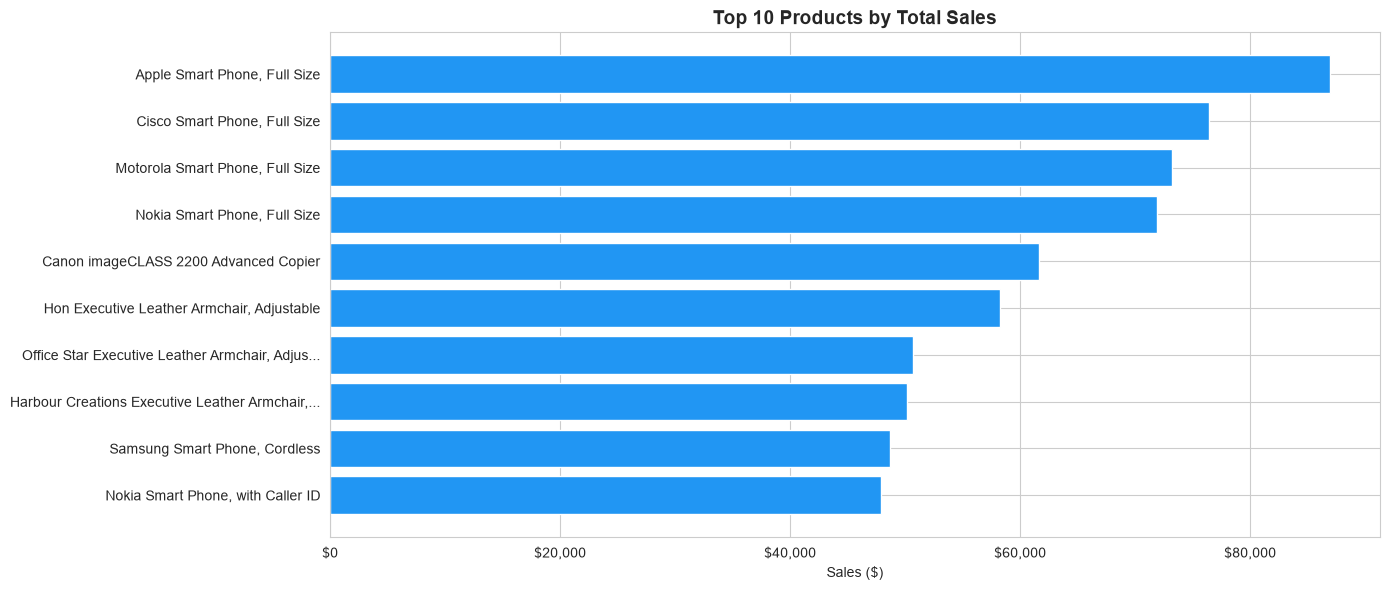

In [13]:
# --- 4.3  Top 10 Products by Sales ---
top10_sales = df.groupby('product_name')['sales'].sum().nlargest(10).reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
# Truncate long product names so labels fit
labels = [name[:45] + '...' if len(name) > 45 else name for name in top10_sales['product_name']]
ax.barh(labels[::-1], top10_sales['sales'].values[::-1], color=COLORS['blue'], edgecolor='white')
ax.set_title('Top 10 Products by Total Sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Sales ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Top Products by Sales:**

These are the revenue champions. However, high sales alone don't guarantee profitability. Cross-referencing with the profit chart below will reveal whether these best-sellers are also profit leaders.

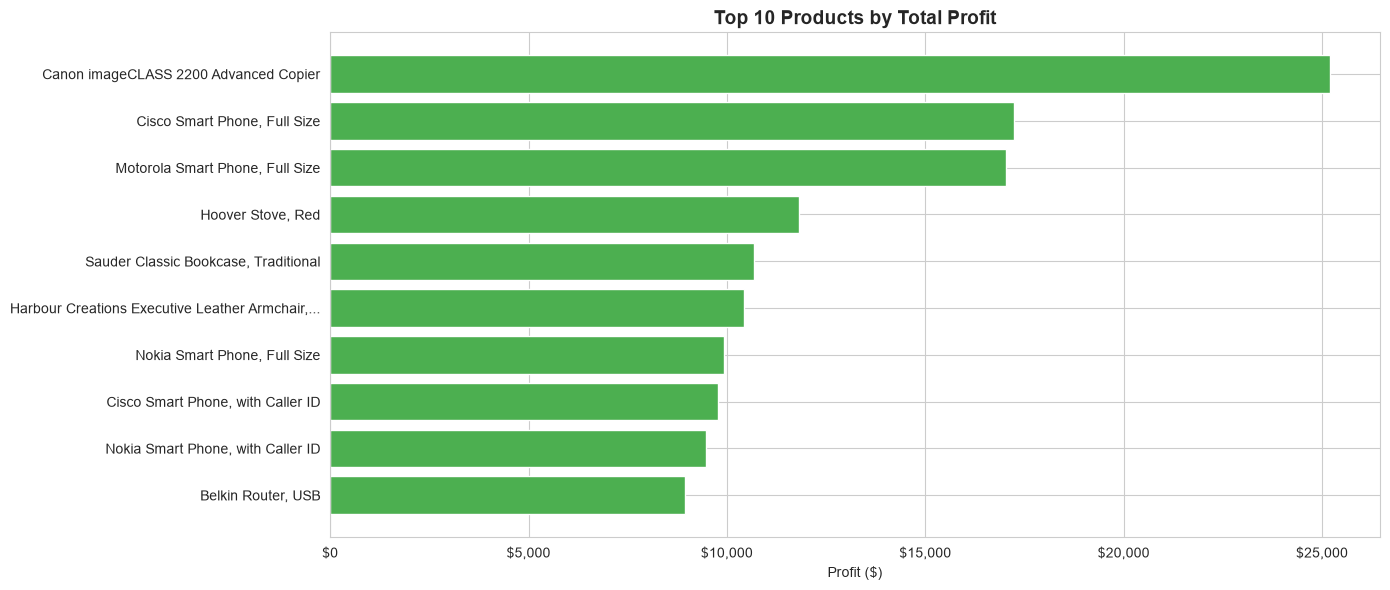

In [14]:
# --- 4.4  Top 10 Products by Profit ---
top10_profit = df.groupby('product_name')['profit'].sum().nlargest(10).reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
labels = [name[:45] + '...' if len(name) > 45 else name for name in top10_profit['product_name']]
ax.barh(labels[::-1], top10_profit['profit'].values[::-1], color=COLORS['green'], edgecolor='white')
ax.set_title('Top 10 Products by Total Profit', fontsize=14, fontweight='bold')
ax.set_xlabel('Profit ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Top Products by Profit:**

These products deliver the most absolute profit. The business should ensure they remain well-stocked, well-promoted, and competitively priced to protect this profit pool.

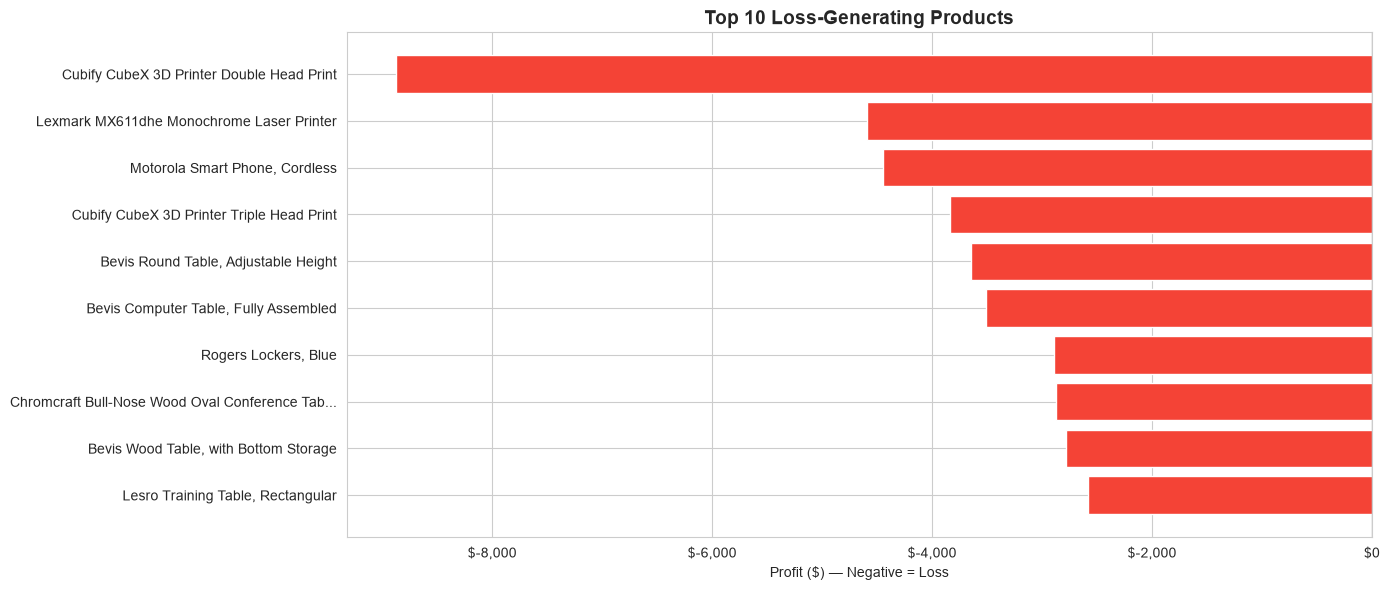

In [15]:
# --- 4.5  Top 10 Loss-Generating Products ---
# Products with the most negative cumulative profit
bottom10_profit = df.groupby('product_name')['profit'].sum().nsmallest(10).reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
labels = [name[:45] + '...' if len(name) > 45 else name for name in bottom10_profit['product_name']]
ax.barh(labels[::-1], bottom10_profit['profit'].values[::-1], color=COLORS['red'], edgecolor='white')
ax.set_title('Top 10 Loss-Generating Products', fontsize=14, fontweight='bold')
ax.set_xlabel('Profit ($) — Negative = Loss')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Loss-Generating Products:**

These products are actively destroying value. For each, the business should investigate whether the losses stem from excessive discounting, high shipping costs, returns, or simply below-cost pricing. A stop-sell or repricing decision may be needed for the worst offenders.

---
## 5. Geographic Analysis

The SuperStore operates across multiple global markets. Let's see where the business is strongest and where it struggles.

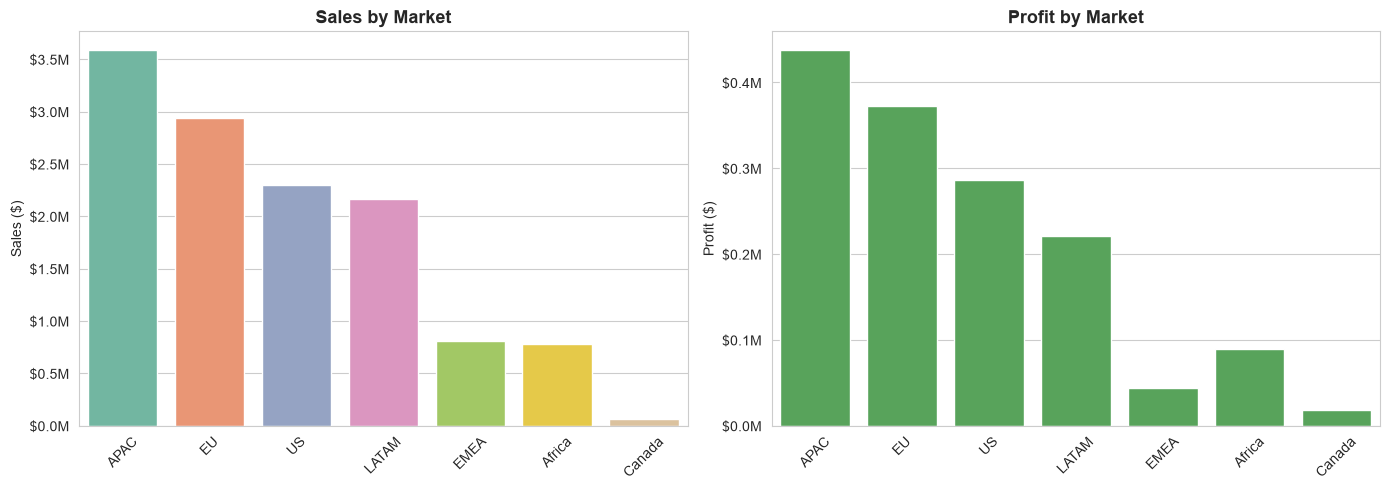

In [16]:
# --- 5.1  Sales & Profit by Market ---
market_perf = df.groupby('market').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).sort_values('sales', ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=market_perf, x='market', y='sales', palette='Set2', ax=axes[0], edgecolor='white')
axes[0].set_title('Sales by Market', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].set_xlabel('')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
axes[0].tick_params(axis='x', rotation=45)

profit_colors_mkt = [COLORS['green'] if p >= 0 else COLORS['red'] for p in market_perf['profit']]
sns.barplot(data=market_perf, x='market', y='profit', palette=profit_colors_mkt, ax=axes[1], edgecolor='white')
axes[1].set_title('Profit by Market', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**📌 Interpretation — Market Performance:**

Markets with high sales but low or negative profit are inefficient — the cost of serving those markets (shipping, discounts, overheads) is eating into margins. The most profitable markets should receive continued investment, while underperformers need operational review.

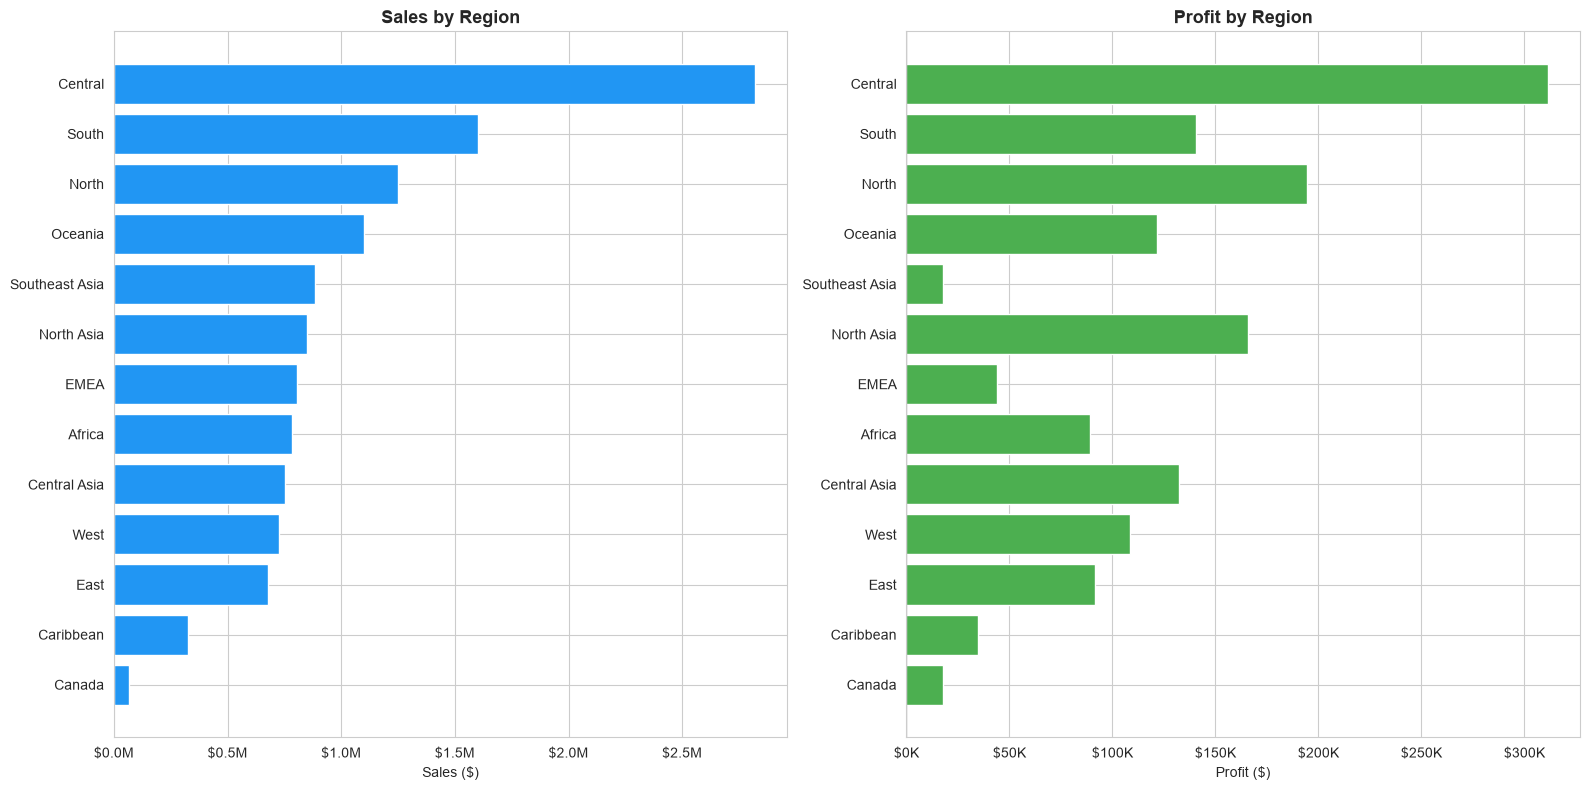

In [17]:
# --- 5.2  Sales & Profit by Region ---
region_perf = df.groupby('region').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).sort_values('sales', ascending=True).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(region_perf['region'], region_perf['sales'], color=COLORS['blue'], edgecolor='white')
axes[0].set_title('Sales by Region', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sales ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

profit_colors_reg = [COLORS['green'] if p >= 0 else COLORS['red'] for p in region_perf['profit']]
axes[1].barh(region_perf['region'], region_perf['profit'], color=profit_colors_reg, edgecolor='white')
axes[1].set_title('Profit by Region', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Profit ($)')
axes[1].axvline(x=0, color='black', linewidth=0.8)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))

plt.tight_layout()
plt.show()

**📌 Interpretation — Regional Performance:**

Regions are a finer granularity than markets. Any region showing red (negative profit) despite meaningful sales is a candidate for strategic review — potential actions include adjusting pricing, reducing discounts, or reconsidering logistics partners.

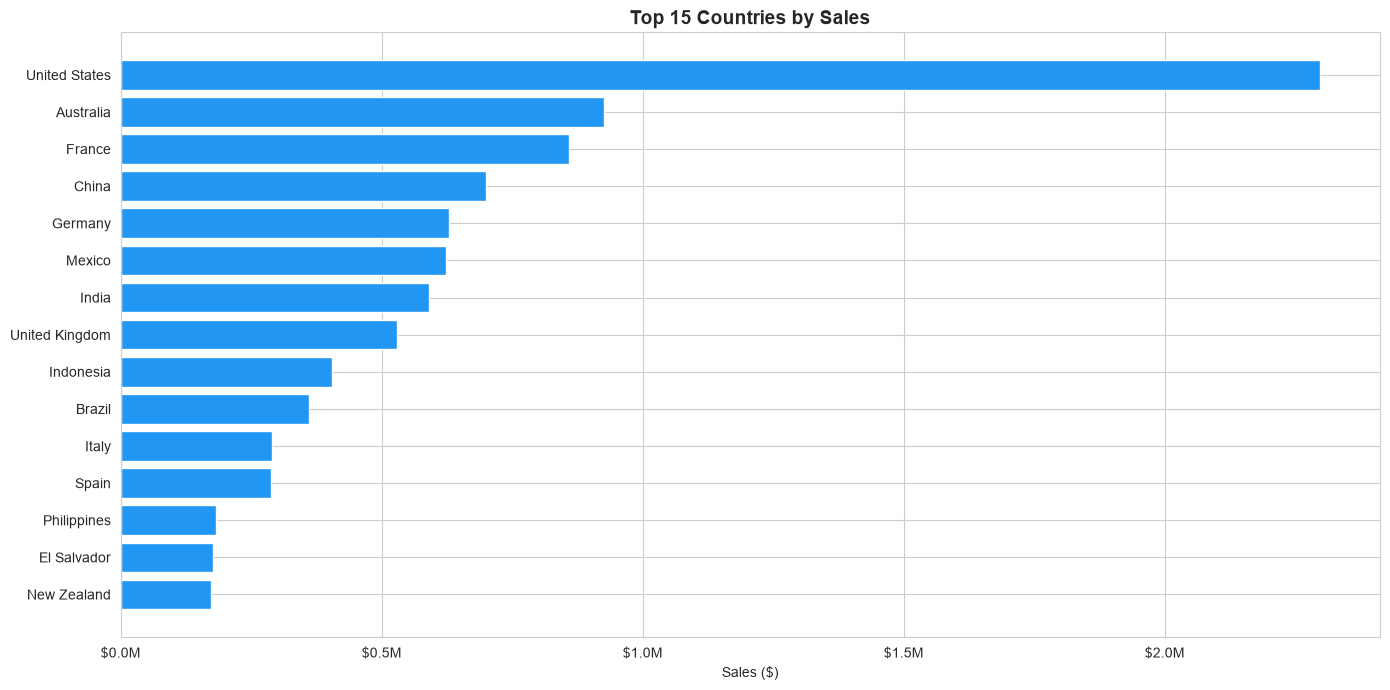

In [18]:
# --- 5.3  Top 15 Countries by Sales ---
top_countries = df.groupby('country').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).sort_values('sales', ascending=False).head(15).reset_index()

fig, ax = plt.subplots(figsize=(14, 7))
bar_colors = [COLORS['green'] if p >= 0 else COLORS['red'] for p in top_countries['profit']]
ax.barh(top_countries['country'][::-1], top_countries['sales'][::-1], color=COLORS['blue'], edgecolor='white')
ax.set_title('Top 15 Countries by Sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Sales ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Top Countries:**

This chart identifies the company's largest country-level markets. The top countries represent significant revenue concentration — diversifying across more countries can reduce geographic risk.

---
## 6. Customer Analysis

Let's examine sales by customer segment and identify the most valuable individual customers.

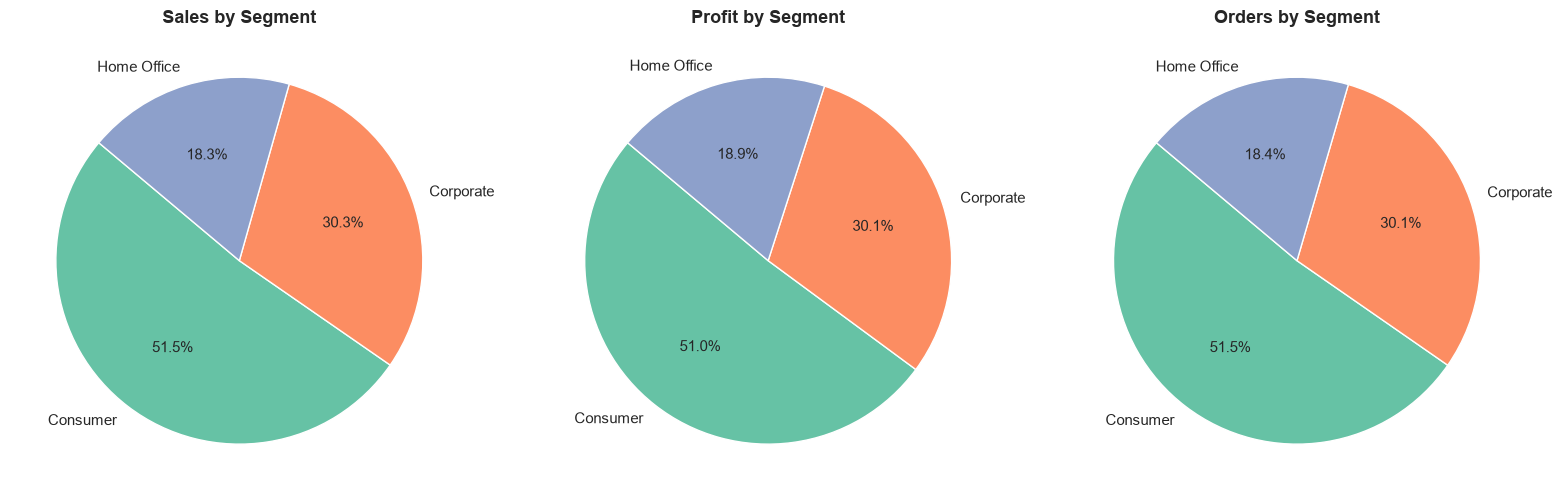

In [19]:
# --- 6.1  Sales & Profit by Segment ---
segment_perf = df.groupby('segment').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum'),
    orders=('order_id', 'nunique')
).sort_values('sales', ascending=False).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Sales by Segment
axes[0].pie(segment_perf['sales'], labels=segment_perf['segment'],
            autopct='%1.1f%%', startangle=140, colors=PALETTE[:3],
            textprops={'fontsize': 11})
axes[0].set_title('Sales by Segment', fontsize=13, fontweight='bold')

# Profit by Segment
axes[1].pie(segment_perf['profit'], labels=segment_perf['segment'],
            autopct='%1.1f%%', startangle=140, colors=PALETTE[:3],
            textprops={'fontsize': 11})
axes[1].set_title('Profit by Segment', fontsize=13, fontweight='bold')

# Orders by Segment
axes[2].pie(segment_perf['orders'], labels=segment_perf['segment'],
            autopct='%1.1f%%', startangle=140, colors=PALETTE[:3],
            textprops={'fontsize': 11})
axes[2].set_title('Orders by Segment', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**📌 Interpretation — Customer Segments:**

The Consumer segment typically makes up the largest share of sales. Comparing each segment's profit share to its sales share reveals margin differences — a segment that contributes a larger slice of profit than sales has above-average margins. Targeted strategies (loyalty programs, bulk pricing) should be tailored per segment.

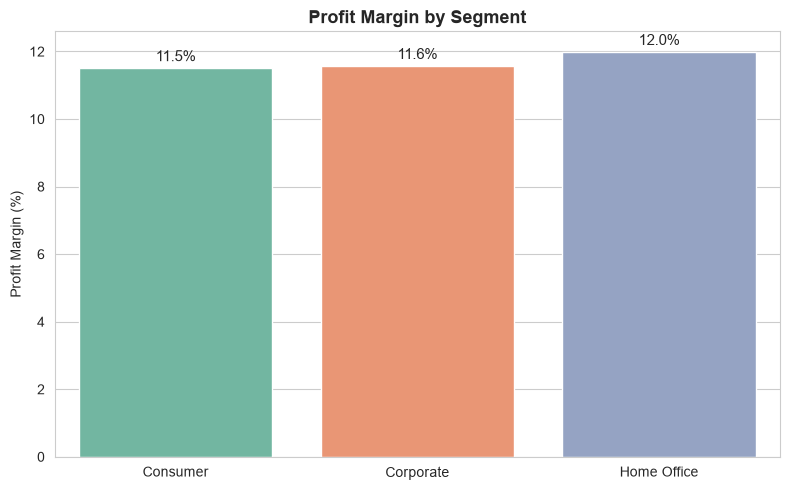

In [20]:
# --- 6.2  Segment Profit Margin Comparison ---
segment_perf['profit_margin'] = (segment_perf['profit'] / segment_perf['sales']) * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=segment_perf, x='segment', y='profit_margin', palette='Set2', ax=ax, edgecolor='white')
ax.set_title('Profit Margin by Segment', fontsize=13, fontweight='bold')
ax.set_ylabel('Profit Margin (%)')
ax.set_xlabel('')
# Add percentage labels
for i, row in segment_perf.iterrows():
    ax.text(i, row['profit_margin'] + 0.2, f"{row['profit_margin']:.1f}%", ha='center', fontsize=11)
plt.tight_layout()
plt.show()

**📌 Interpretation — Segment Margins:**

Comparing margins across segments reveals which group of customers is most profitable per dollar of revenue. If one segment has notably lower margins, it may be receiving excessive discounts or ordering products with thinner margins.

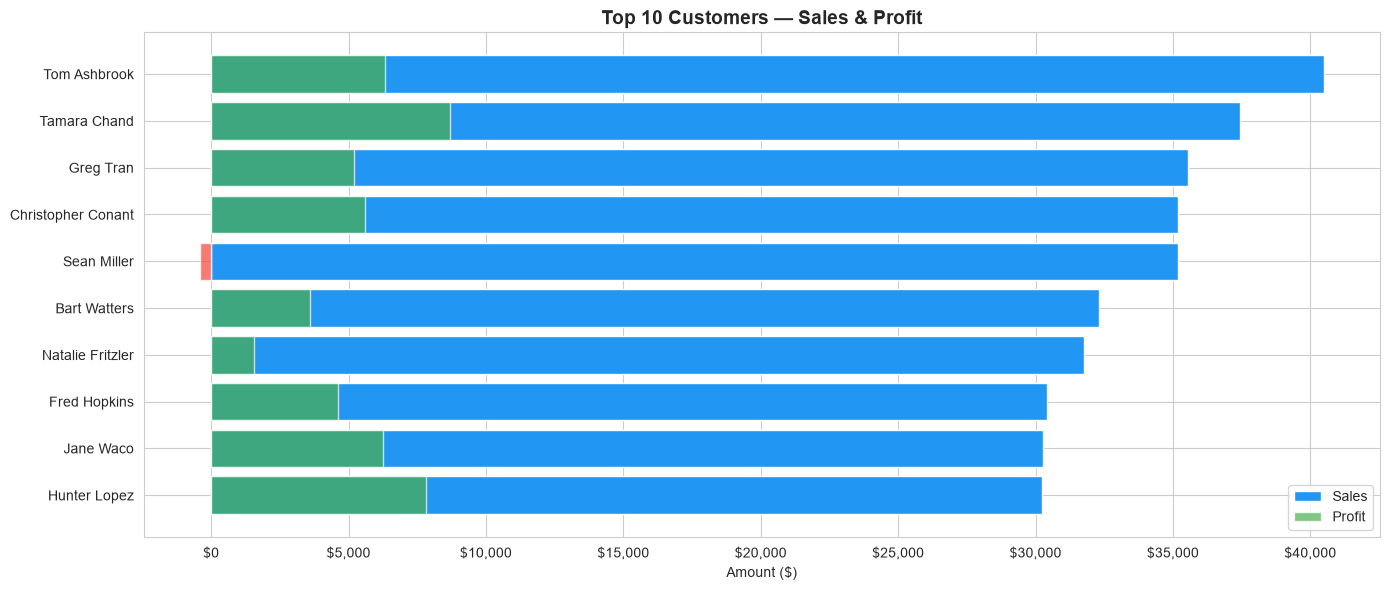

In [21]:
# --- 6.3  Top 10 Customers by Sales ---
top_customers = df.groupby('customer_name').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum'),
    orders=('order_id', 'nunique')
).sort_values('sales', ascending=False).head(10).reset_index()

fig, ax = plt.subplots(figsize=(14, 6))
bar_colors = [COLORS['green'] if p >= 0 else COLORS['red'] for p in top_customers['profit']]
bars = ax.barh(top_customers['customer_name'][::-1], top_customers['sales'][::-1],
               color=COLORS['blue'], edgecolor='white', label='Sales')
ax.barh(top_customers['customer_name'][::-1], top_customers['profit'][::-1],
        color=bar_colors[::-1], edgecolor='white', alpha=0.7, label='Profit')
ax.set_title('Top 10 Customers — Sales & Profit', fontsize=14, fontweight='bold')
ax.set_xlabel('Amount ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend()
plt.tight_layout()
plt.show()

**📌 Interpretation — Top Customers:**

These are the company's highest-revenue customers. Notably, a high-sales customer is not always the most profitable — some may negotiate deep discounts. The overlay of profit on sales helps identify customers who are valuable versus those who are just large.

---
## 7. Discount Analysis

Discounts are a powerful lever, but over-discounting can erode margins. Let's understand the relationship between discounts and profitability.

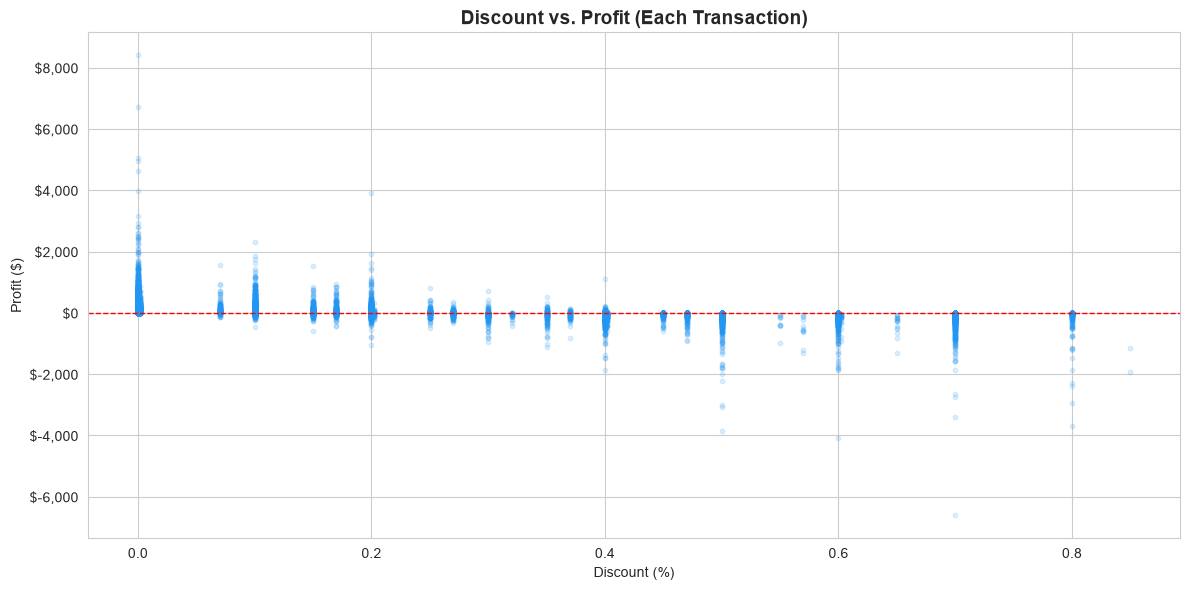

In [22]:
# --- 7.1  Discount vs. Profit — Scatter Plot ---
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(df['discount'], df['profit'], alpha=0.15, s=10, color=COLORS['blue'])
ax.axhline(y=0, color='red', linewidth=1, linestyle='--')  # break-even line
ax.set_title('Discount vs. Profit (Each Transaction)', fontsize=14, fontweight='bold')
ax.set_xlabel('Discount (%)')
ax.set_ylabel('Profit ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

**📌 Interpretation — Discount vs. Profit:**

The scatter plot clearly shows that as discounts increase, the probability of a transaction being unprofitable rises significantly. At higher discount levels (e.g., above 30–40%), most transactions fall below the break-even line. This is strong evidence that the company's discount strategy needs guardrails.

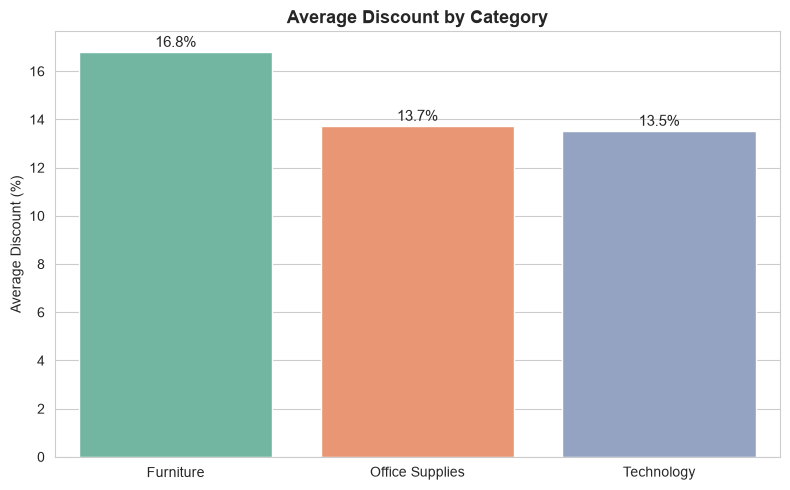

In [23]:
# --- 7.2  Average Discount by Category ---
avg_disc_cat = df.groupby('category')['discount'].mean().sort_values(ascending=False).reset_index()
avg_disc_cat['discount_pct'] = avg_disc_cat['discount'] * 100  # convert to %

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=avg_disc_cat, x='category', y='discount_pct', palette='Set2', ax=ax, edgecolor='white')
ax.set_title('Average Discount by Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Average Discount (%)')
ax.set_xlabel('')
for i, row in avg_disc_cat.iterrows():
    ax.text(i, row['discount_pct'] + 0.2, f"{row['discount_pct']:.1f}%", ha='center', fontsize=11)
plt.tight_layout()
plt.show()

**📌 Interpretation — Category Discounts:**

Some categories receive heavier average discounts than others. If the most-discounted category also has the lowest profit margin, that's a clear signal to tighten discount policies for that category.

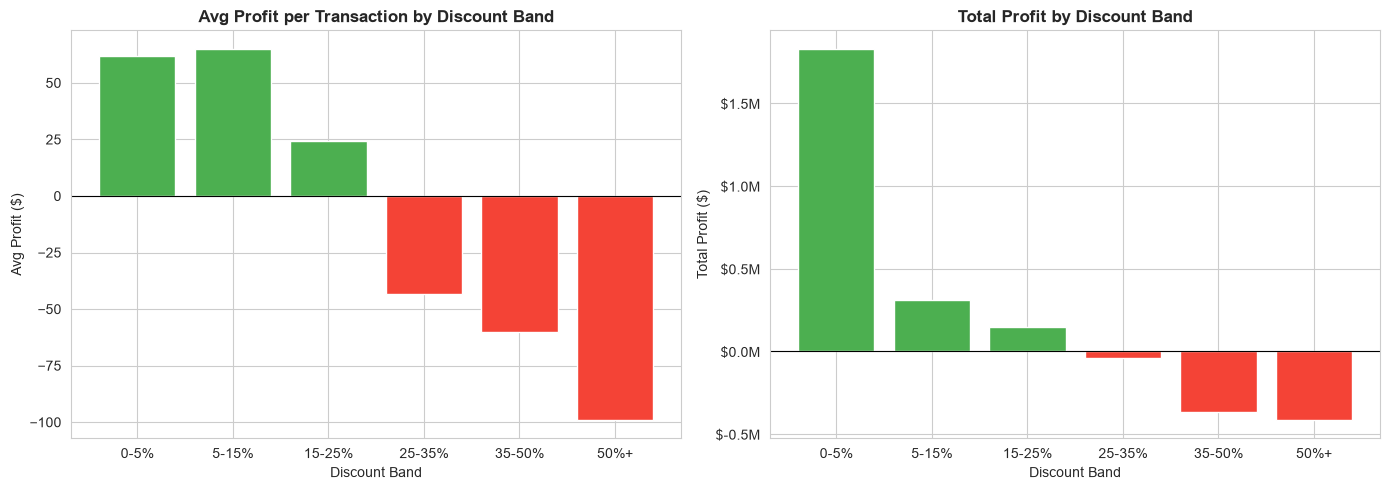

In [24]:
# --- 7.3  Discount Bands vs. Profitability ---
# Create discount bands to group transactions
bins = [0, 0.05, 0.15, 0.25, 0.35, 0.50, 1.0]
labels_bands = ['0-5%', '5-15%', '15-25%', '25-35%', '35-50%', '50%+']
df['discount_band'] = pd.cut(df['discount'], bins=bins, labels=labels_bands, include_lowest=True)

band_perf = df.groupby('discount_band', observed=False).agg(
    avg_profit=('profit', 'mean'),
    total_profit=('profit', 'sum'),
    count=('profit', 'count'),
    avg_margin=('profit_margin', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average Profit per Transaction by Discount Band
bar_colors_band = [COLORS['green'] if p >= 0 else COLORS['red'] for p in band_perf['avg_profit']]
axes[0].bar(band_perf['discount_band'].astype(str), band_perf['avg_profit'],
            color=bar_colors_band, edgecolor='white')
axes[0].axhline(y=0, color='black', linewidth=0.8)
axes[0].set_title('Avg Profit per Transaction by Discount Band', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Avg Profit ($)')
axes[0].set_xlabel('Discount Band')

# Total Profit by Discount Band
bar_colors_band2 = [COLORS['green'] if p >= 0 else COLORS['red'] for p in band_perf['total_profit']]
axes[1].bar(band_perf['discount_band'].astype(str), band_perf['total_profit'],
            color=bar_colors_band2, edgecolor='white')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].set_title('Total Profit by Discount Band', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Profit ($)')
axes[1].set_xlabel('Discount Band')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

# Clean up the helper column
df.drop(columns=['discount_band'], inplace=True)

**📌 Interpretation — Discount Bands:**

This analysis quantifies the damage of over-discounting. The transition from green (profitable) to red (loss-making) at higher discount bands clearly shows the discount threshold beyond which the company loses money. A recommended maximum discount cap can be derived from the band where average profit turns negative.

---
## 8. Shipping Analysis

Shipping mode, speed, and cost are operational levers that impact both customer satisfaction and profitability.

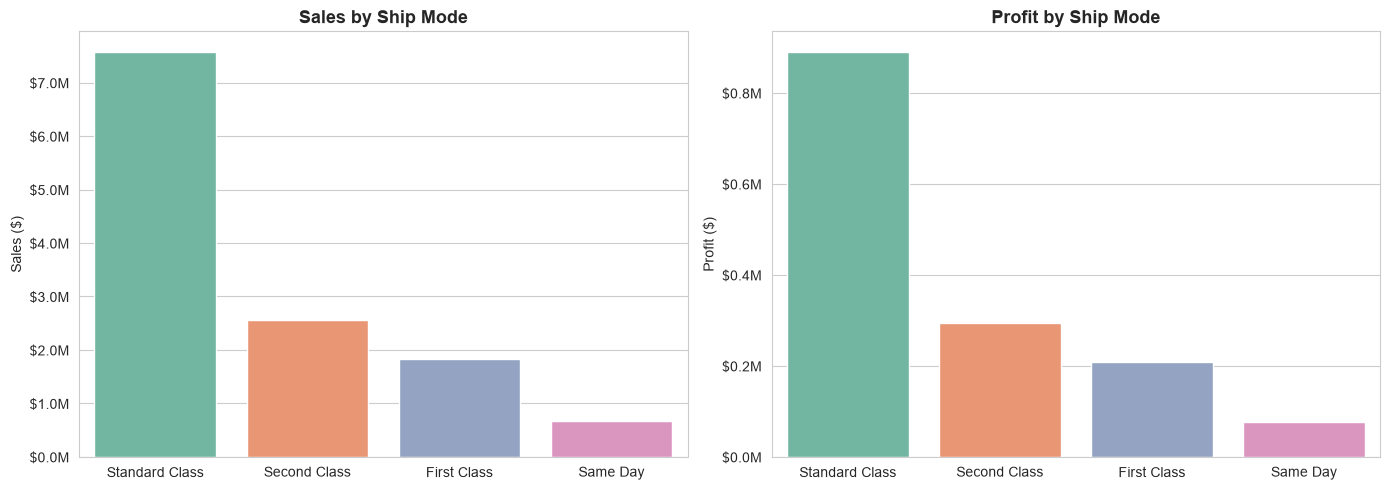

In [25]:
# --- 8.1  Sales by Ship Mode ---
ship_perf = df.groupby('ship_mode').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum'),
    orders=('order_id', 'nunique'),
    avg_shipping_cost=('shipping_cost', 'mean')
).sort_values('sales', ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=ship_perf, x='ship_mode', y='sales', palette='Set2', ax=axes[0], edgecolor='white')
axes[0].set_title('Sales by Ship Mode', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].set_xlabel('')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

sns.barplot(data=ship_perf, x='ship_mode', y='profit', palette='Set2', ax=axes[1], edgecolor='white')
axes[1].set_title('Profit by Ship Mode', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

**📌 Interpretation — Ship Mode Performance:**

Standard Class dominates in volume, which is expected as it's the default/cheapest option. The profit comparison reveals whether faster (and more expensive) shipping modes are still profitable or if their costs eat into margins.

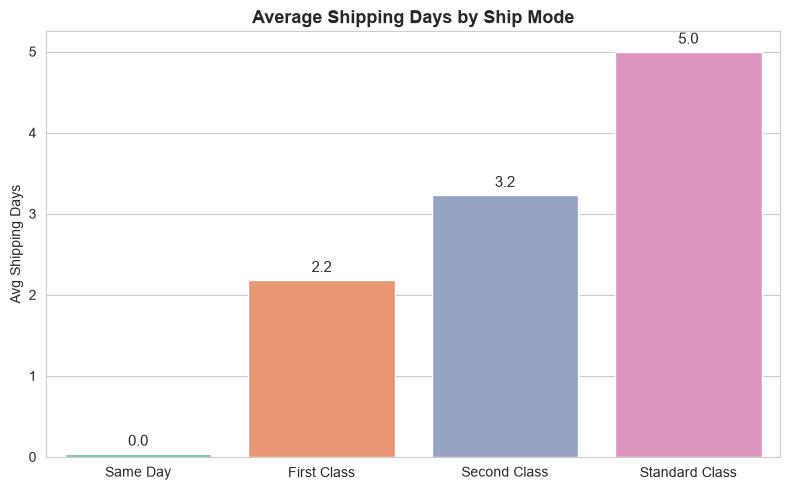

In [26]:
# --- 8.2  Average Shipping Days by Ship Mode ---
avg_ship_days = df.groupby('ship_mode')['shipping_days'].mean().sort_values().reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=avg_ship_days, x='ship_mode', y='shipping_days', palette='Set2', ax=ax, edgecolor='white')
ax.set_title('Average Shipping Days by Ship Mode', fontsize=13, fontweight='bold')
ax.set_ylabel('Avg Shipping Days')
ax.set_xlabel('')
for i, row in avg_ship_days.iterrows():
    ax.text(i, row['shipping_days'] + 0.1, f"{row['shipping_days']:.1f}", ha='center', fontsize=11)
plt.tight_layout()
plt.show()

**📌 Interpretation — Shipping Speed:**

This confirms the expected relationship: faster ship modes deliver in fewer days. The actual averages help set customer expectations and can be used in logistics benchmarking.

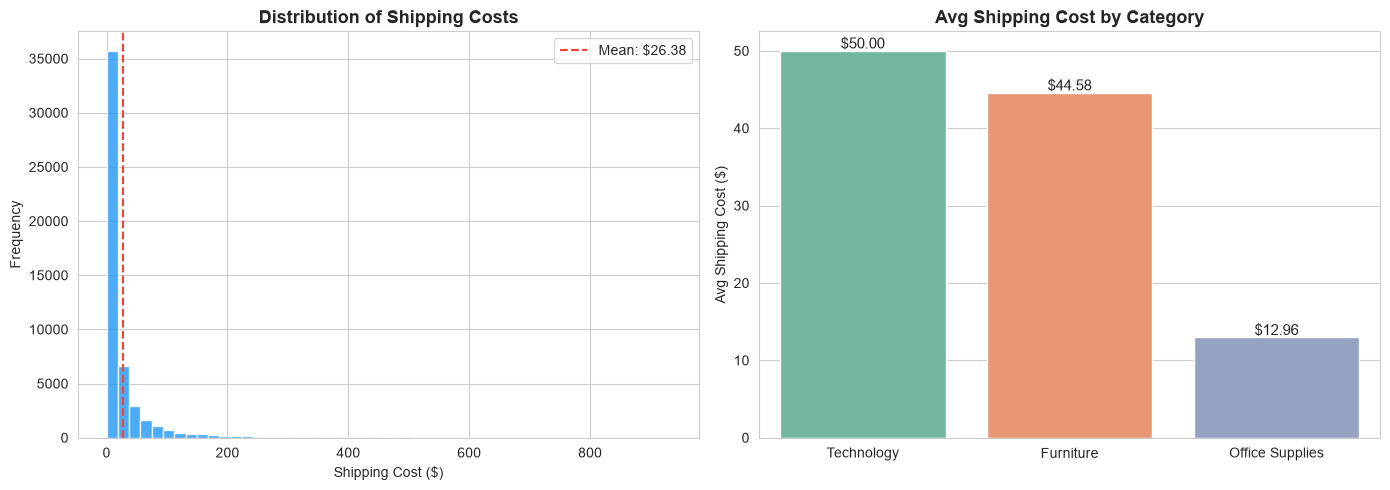

In [27]:
# --- 8.3  Shipping Cost Analysis (Distribution & by Category) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of shipping cost
axes[0].hist(df['shipping_cost'], bins=50, color=COLORS['blue'], edgecolor='white', alpha=0.8)
axes[0].set_title('Distribution of Shipping Costs', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Shipping Cost ($)')
axes[0].set_ylabel('Frequency')
axes[0].axvline(df['shipping_cost'].mean(), color=COLORS['red'], linestyle='--',
                label=f"Mean: ${df['shipping_cost'].mean():.2f}")
axes[0].legend()

# Average shipping cost by category
avg_ship_cat = df.groupby('category')['shipping_cost'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=avg_ship_cat, x='category', y='shipping_cost', palette='Set2', ax=axes[1], edgecolor='white')
axes[1].set_title('Avg Shipping Cost by Category', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Avg Shipping Cost ($)')
axes[1].set_xlabel('')
for i, row in avg_ship_cat.iterrows():
    axes[1].text(i, row['shipping_cost'] + 0.3, f"${row['shipping_cost']:.2f}", ha='center', fontsize=11)

plt.tight_layout()
plt.show()

**📌 Interpretation — Shipping Costs:**

The shipping cost distribution is right-skewed — most orders have moderate shipping costs, but a long tail of expensive shipments exists. The category breakdown reveals which product types are most expensive to ship, which directly affects their profitability.

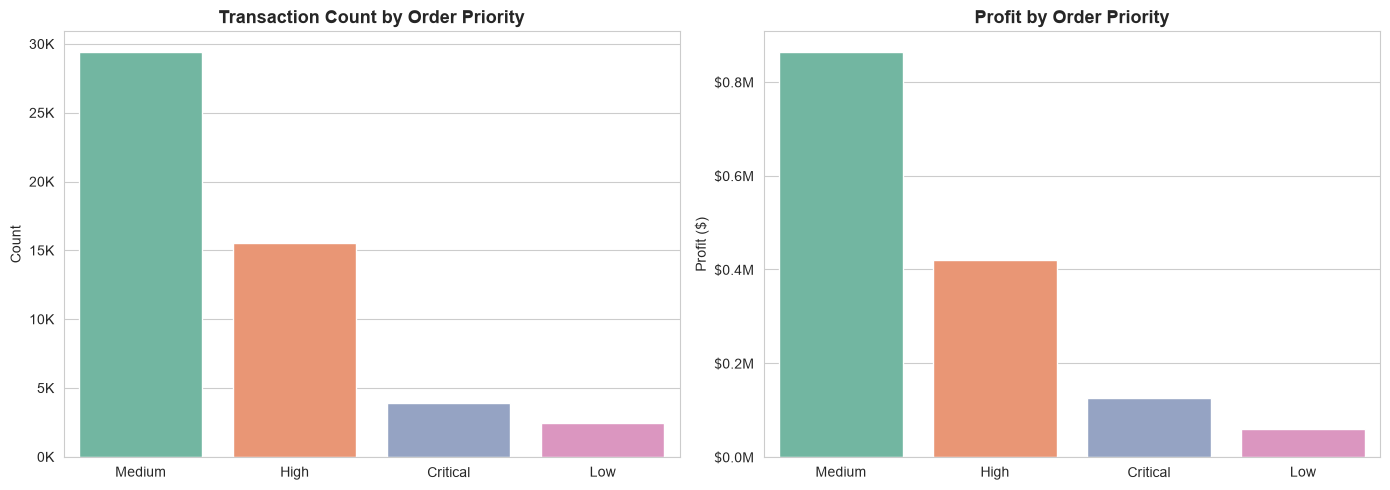

In [28]:
# --- 8.4  Order Priority Analysis ---
priority_perf = df.groupby('order_priority').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum'),
    count=('order_id', 'count')
).sort_values('sales', ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Order count by priority
sns.barplot(data=priority_perf, x='order_priority', y='count', palette='Set2', ax=axes[0], edgecolor='white')
axes[0].set_title('Transaction Count by Order Priority', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))

# Profit by priority
sns.barplot(data=priority_perf, x='order_priority', y='profit', palette='Set2', ax=axes[1], edgecolor='white')
axes[1].set_title('Profit by Order Priority', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Profit ($)')
axes[1].set_xlabel('')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

plt.tight_layout()
plt.show()

**📌 Interpretation — Order Priority:**

The order priority distribution shows how urgently customers need their orders. If higher-priority (rush) orders are less profitable, the company may not be charging enough of a premium for expedited fulfillment. Conversely, if they're more profitable, the business should consider promoting express options.

---
## 9. Key Findings & Conclusions

### 📊 Summary of Key Findings

After a thorough exploratory analysis of the SuperStore's global sales data (51,290 transactions spanning 2011–2014), the following key insights emerge:

#### 📈 Growth & Trends
- **Consistent year-over-year growth** in both sales and profit across the four-year period.
- **Strong seasonality** — sales peak during November and December each year, likely driven by holiday demand.
- The 3-month moving average confirms the upward trajectory is sustained, not driven by one-off spikes.

#### 🛍️ Product Insights
- Product categories differ significantly in both revenue contribution and profitability.
- Several sub-categories are **chronically unprofitable** despite generating meaningful revenue — these need pricing or assortment review.
- A small number of products generate outsized losses — the top 10 loss-makers should be flagged for immediate review.

#### 🌍 Geographic Insights
- The business spans 7 global markets, but **profitability varies widely by market and region**.
- Some regions are unprofitable despite decent sales volumes, suggesting operational inefficiencies or over-discounting.
- Revenue is concentrated in a handful of top countries.

#### 👥 Customer Segments
- The Consumer segment drives the most volume, but margin comparisons across segments reveal opportunities for differentiated strategies.
- Top customers by revenue are not always the most profitable ones.

#### 💸 Discounting — The Critical Lever
- **Discounting has the clearest negative correlation with profit.** Transactions with discounts above ~20–30% are overwhelmingly unprofitable.
- Nearly a quarter of all line items operate at a loss, and heavy discounting is a primary driver.
- **Recommendation:** Implement a discount cap policy — discounts beyond a calculated threshold destroy more value than they create.

#### 🚚 Shipping & Operations
- Standard Class is the dominant ship mode. Faster modes cost more but serve fewer orders.
- Shipping cost varies by category — bulky or heavy product categories cost more to ship.
- Shipping speed aligns with expectations by mode.

---

### 🎯 Recommended Next Steps

1. **Implement discount guardrails** — cap discounts at the level where average profit turns negative.
2. **Review loss-making sub-categories and products** — reprice, renegotiate supplier terms, or delist.
3. **Investigate unprofitable regions** — assess whether logistics costs, local pricing, or competitive dynamics are the root cause.
4. **Develop segment-specific strategies** — tailor promotions, pricing, and service levels by customer segment.
5. **Leverage seasonality** — pre-stock for peak months and run targeted campaigns during off-peak months.
6. **Build predictive models** — use these findings to build sales forecasting and customer segmentation models.

---

*Notebook created for the SuperStore Sales Analytics project.*